## 📓 Notebook 05: Interaction & Polynomial Features

**Skills practiced:** Multiplying columns into interaction features, `PolynomialFeatures(degree=2)`, grouped line plots.

**Goal:** Build temperature×humidity and weekend×hour interactions plus a squared temperature term, and prove with plots or RMSE that each captures something real.

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import root_mean_squared_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import PolynomialFeatures

In [31]:
x_train=pd.read_csv('../data/processed/stage_2/x_train_sc.csv')
x_test=pd.read_csv('../data/processed/stage_2/x_test_sc.csv')
y_train=pd.read_csv('../data/processed/y_train.csv')
y_test=pd.read_csv('../data/processed/y_test.csv')
x_train_unscaled=pd.read_csv('../data/processed/stage_2/x_train_unsc.csv')

In [32]:
x_train_raw=x_train.copy()
x_test_raw=x_test.copy()

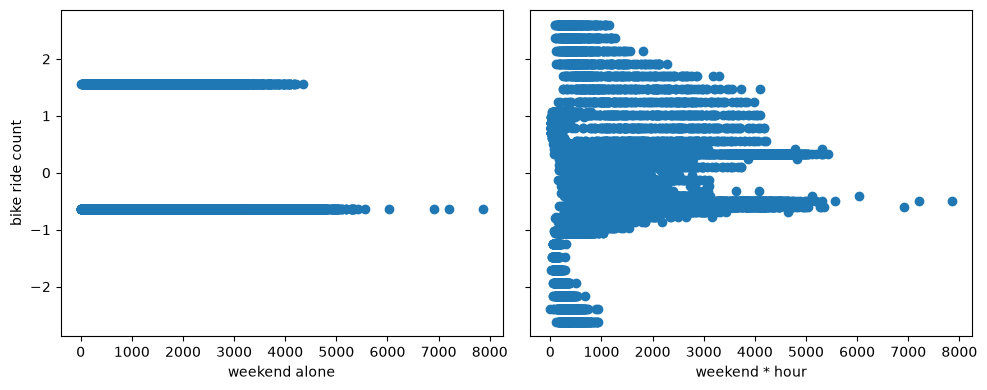

In [33]:
x_train['weekend_hour']=x_train['is_weekend']*x_train['hour']
x_test['weekend_hour']=x_test['is_weekend']*x_test['hour']

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)

axes[0].set_ylabel('bike ride count')
axes[0].scatter(y_train['cnt'],x_train['is_weekend'])
axes[0].set_xlabel('weekend alone')

axes[1].scatter(y_train['cnt'],x_train['weekend_hour'])
axes[1].set_xlabel('weekend * hour')

plt.tight_layout()
plt.show()

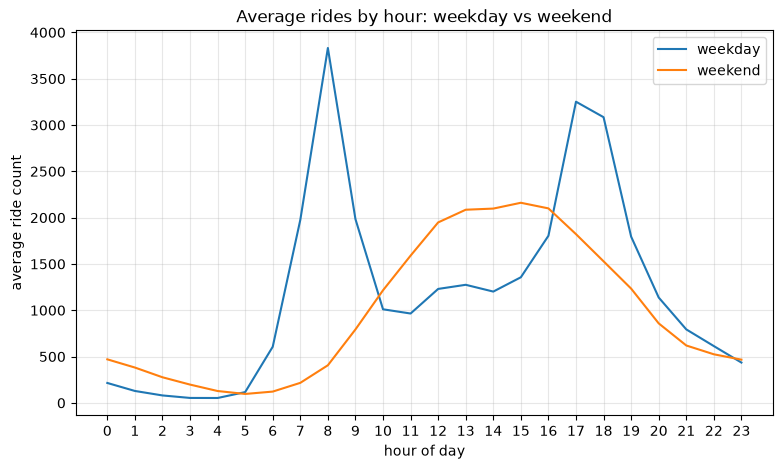

In [34]:
plot_df = x_train_unscaled.join(y_train['cnt'])

ax = plot_df.groupby(['is_weekend', 'hour'])['cnt'].mean().unstack(0).plot(figsize=(9, 5))
ax.set_xticks(range(24))
ax.set_xlabel('hour of day')
ax.set_ylabel('average ride count')
ax.set_title('Average rides by hour: weekday vs weekend')
ax.legend(['weekday', 'weekend'])
ax.grid(alpha=0.3)

plt.savefig('../outputs/figures/hourly_rides.png', dpi=200, bbox_inches='tight')
plt.show()

In [35]:

num_cols = ['t1', 't2', 'hum', 'wind_speed']
pf = PolynomialFeatures(degree=2, include_bias=False)
pf.set_output(transform='pandas')

pf.fit_transform(x_train[num_cols])
pf.transform(x_test[num_cols])


print(x_train.columns)

Index(['Unnamed: 0', 't1', 't2', 'hum', 'wind_speed', 'is_holiday',
       'is_weekend', 'hour', 'weather_Broken clouds', 'weather_Clear',
       'weather_Cloudy', 'weather_Light rain',
       'weather_Rain with thunderstorm', 'weather_Scattered clouds',
       'weather_Snowfall', 'season_Fall', 'season_Spring', 'season_Summer',
       'season_Winter', 'weekend_hour'],
      dtype='str')


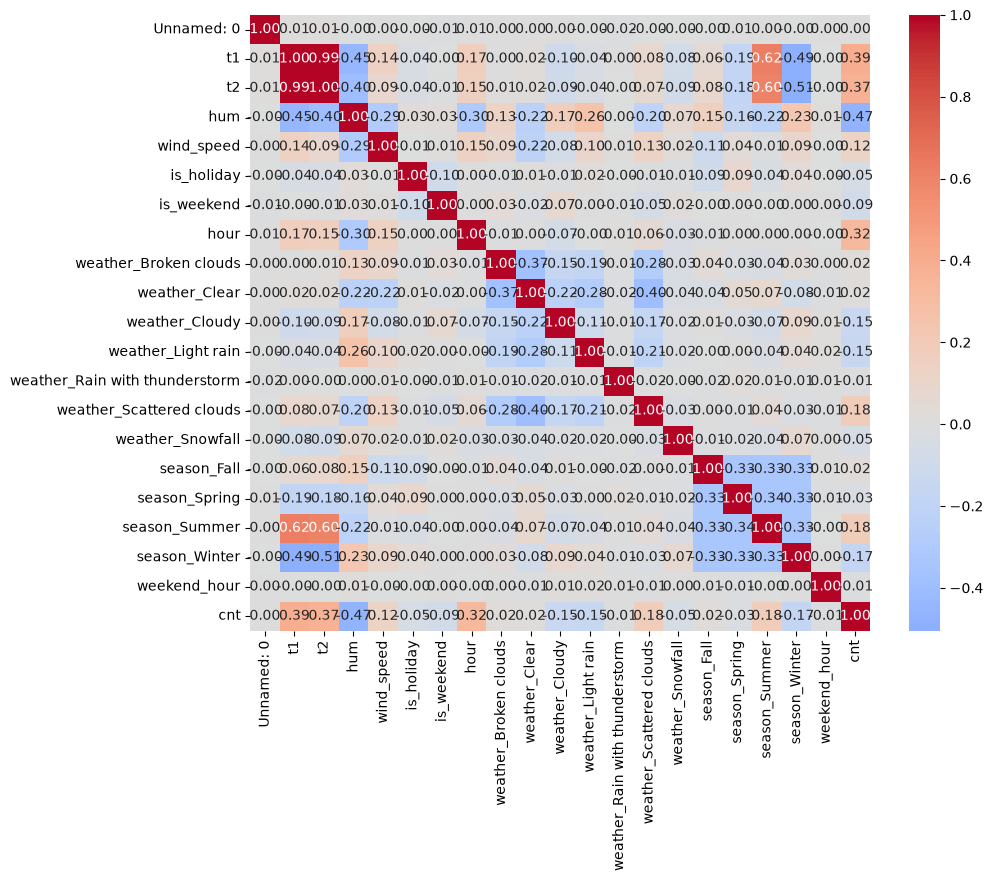

In [36]:
corr_df = x_train.join(y_train['cnt'])

plt.figure(figsize=(10, 8))
sns.heatmap(corr_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.show()

In [37]:
for name, (tr, te) in {
    'raw': (x_train_raw, x_test_raw),
    'polynomial featured': (x_train, x_test),
}.items():
    rf = RandomForestRegressor(n_estimators=250, random_state=42, n_jobs=-1)
    rf.fit(tr, y_train['cnt'])
    print(name, round(root_mean_squared_error(y_test['cnt'], rf.predict(te)), 2))

raw 261.01
polynomial featured 256.91


In [38]:
x_train.to_csv('../data/processed/stage_3/x_train_poly.csv')
x_test.to_csv('../data/processed/stage_3/x_test_poly.csv')